# 7.0 - Performance da versao final no conjunto de teste

Versao final = `config.py`: persistencia de 15 a 60 min, LightGBM (`MODELO_ATUAL`) de 90 a 360 min.

**O problema e de classificacao.** Na cabeca k, cada linha tem:
- X = as colunas de `MODELO_ATUAL` no instante t (6 tags, Hora, Minuto, Dia_Semana, `score_atual`, `score_max_30`);
- y = 1 se o score da camera em t + k for >= 0,5 (pluma), se nao 0.

O modelo devolve a probabilidade de y = 1. O **limiar** transforma a probabilidade em alarme (1) ou nao (0).

**Conjunto de teste** = hold out (ultimos 20% do periodo). Os modelos e os limiares sao feitos SO com o treino; o teste so mede.

| Metrica | Pergunta | Depende do limiar? |
|---|---|---|
| AP | os instantes de pluma recebem as maiores probabilidades? | nao |
| Precisao | dos alarmes, quantos eram pluma? | sim |
| Recall | das plumas, quantas tiveram alarme? | sim |
| F1 | media harmonica de precisao e recall (so e alta se as duas forem altas) | sim |

**Como escolher o limiar.** Abaixar o limiar sobe o recall e desce a precisao (mais alarmes, mais falsos). As opcoes:
- limiar fixo 0,5: nos modelos (probabilidades baixas) quase nao alarma -> recall perto de zero;
- maximo **F1** (beta = 1): precisao e recall com o mesmo peso, as duas altas ao mesmo tempo;
- maximo **F2** (beta = 2): o recall pesa 4 vezes mais (perde menos plumas, mais alarmes falsos);
- **equilibrio**: maximo de min(precisao, recall), a menor das duas o mais alta possivel.

O limiar e escolhido nas previsoes fora da amostra do CV temporal do TREINO (modelos que nao viram aquelas linhas).
Aqui comparamos as tres no teste; o config usa `BETA_LIMIAR` (1 = F1).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import PATH_REPORTS, CABECAS_POSSIVEIS, PREVISOR_POR_CABECA, MODELOS, MODELO_ATUAL, BETA_LIMIAR
from ml_atmospheric_emission.dataset import load_interim
from ml_atmospheric_emission.features import create_training_dataset
from ml_atmospheric_emission.modeling.train import train_head_models, choose_thresholds
from ml_atmospheric_emission.modeling.evaluate import split_holdout, performance_table
from ml_atmospheric_emission.plots import plot_precision_recall

## 1. Dados: treino e teste (o mesmo corte dos notebooks 3.0 a 6.0)

In [3]:
ds = create_training_dataset(load_interim(), CABECAS_POSSIVEIS)
dx_treino, dx_teste = split_holdout(ds)
print('Dias no teste:', dx_teste['Data'].dt.normalize().nunique())

Treino ate: 2026-10-02 23:15:00 | linhas treino: 11598 | linhas hold out: 2900
Dias no teste: 12


## 2. Limiares escolhidos no treino (F1, F2 e equilibrio)

Precisao, recall e F-beta aqui sao do TREINO (fora da amostra do CV): e o que se espera, antes de ver o teste.

In [4]:
limiares_f1 = choose_thresholds(dx_treino, PREVISOR_POR_CABECA, MODELOS, beta=1)
limiares_f2 = choose_thresholds(dx_treino, PREVISOR_POR_CABECA, MODELOS, beta=2)
limiares_eq = choose_thresholds(dx_treino, PREVISOR_POR_CABECA, MODELOS, criterio='equilibrio')
print('Maximo F1 (beta = 1):')
print(limiares_f1.round(3).to_string(index=False))
print()
print('Maximo F2 (beta = 2):')
print(limiares_f2.round(3).to_string(index=False))
print()
print('Equilibrio (maximo de min(precisao, recall)):')
print(limiares_eq[['minutos', 'previsor', 'limiar', 'precisao', 'recall']].round(3).to_string(index=False))

90 min: ok


120 min: ok


180 min: ok


240 min: ok


360 min: ok


...

90 min: ok


120 min: ok


180 min: ok


240 min: ok


360 min: ok
Maximo F1 (beta = 1):
 minutos     previsor  limiar  precisao  recall  f_beta
      15 persistencia   0.496     0.592   0.593   0.592
      30 persistencia   0.495     0.510   0.515   0.513
      60 persistencia   0.455     0.405   0.428   0.416
      90  base_estado   0.191     0.330   0.390   0.358
     120  base_estado   0.121     0.200   0.438   0.275
     180  base_estado   0.061     0.175   0.652   0.275
     240  base_estado   0.066     0.146   0.609   0.236
     360  base_estado   0.055     0.150   0.640   0.243

Maximo F2 (beta = 2):
 minutos     previsor  limiar  precisao  recall  f_beta
      15 persistencia   0.074     0.374   0.791   0.647
      30 persistencia   0.084     0.335   0.696   0.573
      60 persistencia   0.033     0.246   0.620   0.476
      90  base_estado   0.094     0.213   0.570   0.427
     120  base_estado   0.045     0.152   0.754   0.420
     180  base_estado   0.043     0.158   0.745   0.427
     240  base_estado   0.045     0.140   0.736

## 3. Versao final treinada no treino, prevendo o teste

In [5]:
modelos_treino = train_head_models(dx_treino, PREVISOR_POR_CABECA, MODELOS)
resultados = {}
for minutos in CABECAS_POSSIVEIS:
    dx = dx_teste[dx_teste['y_' + str(minutos)].notna()].reset_index(drop=True)
    tabela = pd.DataFrame({'Data': dx['Data'], 'y_true': (dx['y_' + str(minutos)] >= 0.5).astype(int), 'persistencia': dx['y']})
    if PREVISOR_POR_CABECA[minutos] == 'persistencia':
        tabela['sistema'] = dx['y'].values
    else:
        tabela['sistema'] = modelos_treino[minutos].predict_proba(dx[MODELO_ATUAL])[:, 1]
    resultados[minutos] = tabela

## 4. Performance no teste

`horas_*_dia`: cada linha e 5 minutos. `horas_alarme_dia` = horas com alarme por dia; `horas_pluma_sem_alarme_dia` = horas de pluma
que o alarme perdeu. `f1_persistencia_05`: a regra simples "a camera mostra pluma agora" (score >= 0,5), para comparar.

In [6]:
dict_f1 = dict(zip(limiares_f1['minutos'], limiares_f1['limiar']))
dict_f2 = dict(zip(limiares_f2['minutos'], limiares_f2['limiar']))
dict_eq = dict(zip(limiares_eq['minutos'], limiares_eq['limiar']))
tabela_f1 = performance_table(resultados, dict_f1)
tabela_f2 = performance_table(resultados, dict_f2)
tabela_eq = performance_table(resultados, dict_eq)
print('Limiar de maximo F1 (precisao e recall com o mesmo peso):')
print(tabela_f1.round(3).to_string(index=False))
print()
print('Limiar de maximo F2 (recall pesa mais):')
print(tabela_f2.round(3).to_string(index=False))

Limiar de maximo F1 (precisao e recall com o mesmo peso):
 minutos  prevalencia    ap  limiar  precisao  recall    f1  horas_alarme_dia  horas_pluma_dia  horas_pluma_sem_alarme_dia  ap_persistencia  f1_persistencia_05
      15        0.123 0.721   0.496     0.709   0.711 0.710             2.479            2.472                       0.715            0.721               0.708
      30        0.124 0.632   0.495     0.641   0.643 0.642             2.479            2.472                       0.882            0.632               0.640
      60        0.124 0.471   0.455     0.530   0.551 0.540             2.569            2.472                       1.111            0.471               0.537
      90        0.125 0.513   0.191     0.534   0.594 0.563             2.743            2.465                       1.000            0.368               0.473
     120        0.125 0.469   0.121     0.385   0.755 0.510             4.840            2.465                       0.604            0.323   

In [7]:
#The three approaches side by side in the test (precision / recall / F1 / alarm hours per day)
comparacao = pd.DataFrame({'minutos': tabela_f1['minutos']})
for nome, tabela in [('f1', tabela_f1), ('f2', tabela_f2), ('equilibrio', tabela_eq)]:
    comparacao['P_' + nome] = tabela['precisao'].values
    comparacao['R_' + nome] = tabela['recall'].values
    comparacao['F1_' + nome] = tabela['f1'].values
    comparacao['horas_' + nome] = tabela['horas_alarme_dia'].values
comparacao.round(2)

,minutos,P_f1,R_f1,F1_f1,horas_f1,P_f2,R_f2,F1_f2,horas_f2,P_equilibrio,R_equilibrio,F1_equilibrio,horas_equilibrio
0,15,0.71,0.71,0.71,2.48,0.57,0.86,0.69,3.74,0.71,0.71,0.71,2.48
1,30,0.64,0.64,0.64,2.48,0.54,0.80,0.65,3.64,0.64,0.64,0.64,2.47
2,60,0.53,0.55,0.54,2.57,0.45,0.78,0.57,4.24,0.54,0.53,0.53,2.47
3,90,0.53,0.59,0.56,2.74,0.39,0.82,0.52,5.22,0.56,0.56,0.56,2.47
4,120,0.38,0.75,0.51,4.84,0.26,0.99,0.42,9.27,0.48,0.50,0.49,2.57
5,180,0.30,0.92,0.45,7.57,0.28,0.95,0.44,8.26,0.37,0.59,0.46,3.90
6,240,0.29,0.85,0.43,7.15,0.27,0.91,0.42,8.19,0.34,0.66,0.44,4.80
7,360,0.31,0.93,0.46,7.45,0.29,0.96,0.45,8.06,0.32,0.92,0.47,7.15


### Qual abordagem?

- **F2** sobe pouco o recall nas cabecas longas (ja esta em ~0,9 com F1) e derruba a precisao nas curtas.
- **Equilibrio** ganha poucos pontos de precisao nas cabecas de 180 e 240 min, mas perde muito recall, e o F1 fica igual.
- Nas cabecas longas a curva precisao x recall (grafico abaixo) quase nao passa de ~0,4 de precisao com um recall razoavel:
  as duas altas ao mesmo tempo nao existem nesses horizontes. Entre os pontos possiveis, o **maximo F1** e o que mantem
  o recall alto (o que importa no longo prazo) sem derrubar a precisao. Por isso `BETA_LIMIAR = 1`.

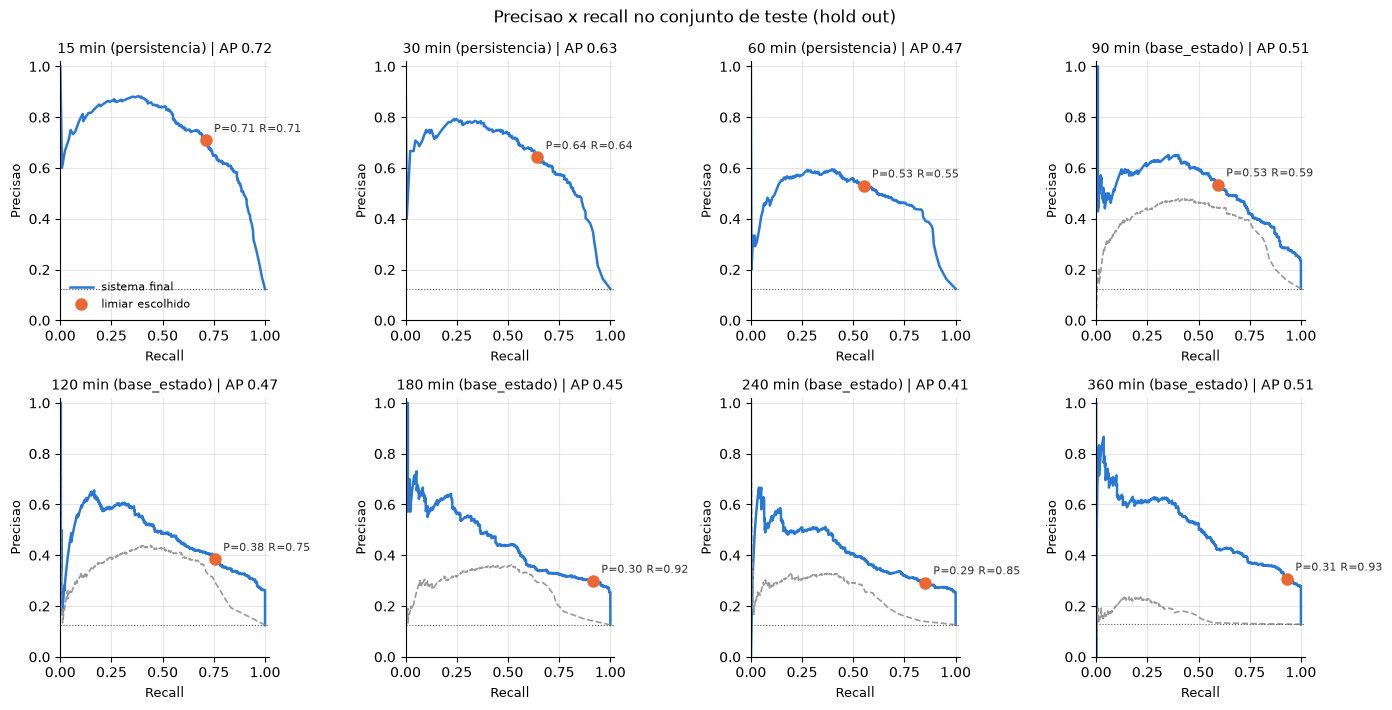

In [8]:
plot_precision_recall(resultados, tabela_f1, PREVISOR_POR_CABECA, PATH_REPORTS / 'figures/performance_teste.png')

## 5. Resumo

In [9]:
if BETA_LIMIAR == 1:
    tabela_final = tabela_f1
else:
    tabela_final = tabela_f2
tabela_final.to_csv(PATH_REPORTS / 'performance_teste.csv', index=False)
colunas = ['minutos', 'ap', 'limiar', 'precisao', 'recall', 'f1', 'f1_persistencia_05', 'horas_alarme_dia', 'horas_pluma_dia']
print('Versao final no teste (limiar com BETA_LIMIAR =', BETA_LIMIAR, '):')
print(tabela_final[colunas].round(3).to_string(index=False))
print()
print('F1 medio das cabecas com modelo:', round(tabela_final[tabela_final['minutos'] >= 90]['f1'].mean(), 3),
      '| com a regra simples (score >= 0,5):', round(tabela_final[tabela_final['minutos'] >= 90]['f1_persistencia_05'].mean(), 3))

Versao final no teste (limiar com BETA_LIMIAR = 1 ):
 minutos    ap  limiar  precisao  recall    f1  f1_persistencia_05  horas_alarme_dia  horas_pluma_dia
      15 0.721   0.496     0.709   0.711 0.710               0.708             2.479            2.472
      30 0.632   0.495     0.641   0.643 0.642               0.640             2.479            2.472
      60 0.471   0.455     0.530   0.551 0.540               0.537             2.569            2.472
      90 0.513   0.191     0.534   0.594 0.563               0.473             2.743            2.465
     120 0.469   0.121     0.385   0.755 0.510               0.439             4.840            2.465
     180 0.454   0.061     0.298   0.915 0.450               0.343             7.569            2.465
     240 0.411   0.066     0.292   0.850 0.435               0.321             7.153            2.458
     360 0.506   0.055     0.307   0.932 0.461               0.226             7.451            2.451

F1 medio das cabecas com mod